In [3]:

# Customer Retention & Cohort Analysis
# Import pandas and load the retention data

import pandas as pd

# Load the CSV file from the reports folder
df = pd.read_csv("../reports/05_Customer_Retention/cohort_retention.csv")

# Display the first 5 rows
df.head()


,cohort_month,cohort_size,month_1_customers,month_2_customers,month_1_retention_pct,month_2_retention_pct
0,2016-09,1,0,0,0.00,0.00
1,2016-10,262,0,0,0.00,0.00
2,2016-12,1,1,0,100.00,0.00
3,2017-01,717,2,2,0.28,0.28
4,2017-02,1628,3,5,0.18,0.31


In [5]:

# Check data types and missing values

# Display number of rows and columns
print("Dataset Shape:", df.shape)

# Check column data types
print("\nData Types:")
print(df.dtypes)

# Check missing values in each column
print("\nMissing Values:")
print(df.isnull().sum())


Dataset Shape: (23, 6)

Data Types:
cohort_month              object
cohort_size                int64
month_1_customers          int64
month_2_customers          int64
month_1_retention_pct    float64
month_2_retention_pct    float64
dtype: object

Missing Values:
cohort_month             0
cohort_size              0
month_1_customers        0
month_2_customers        0
month_1_retention_pct    0
month_2_retention_pct    0
dtype: int64


In [9]:

# Verify the retention dataset

# Check the number of rows and columns
print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

# Check for missing values
print("Total Missing Values:", df.isnull().sum().sum())


Total Rows: 23
Total Columns: 6
Total Missing Values: 0


In [11]:

# Prepare retention data for visualization

# Select the cohort month and retention percentages
retention_data = df[[
    "cohort_month",
    "month_1_retention_pct",
    "month_2_retention_pct"
]].copy()

# Rename columns for easier understanding
retention_data.columns = [
    "Cohort Month",
    "Month 1",
    "Month 2"
]

# Display the first 5 rows
retention_data.head()


,Cohort Month,Month 1,Month 2
0,2016-09,0.00,0.00
1,2016-10,0.00,0.00
2,2016-12,100.00,0.00
3,2017-01,0.28,0.28
4,2017-02,0.18,0.31


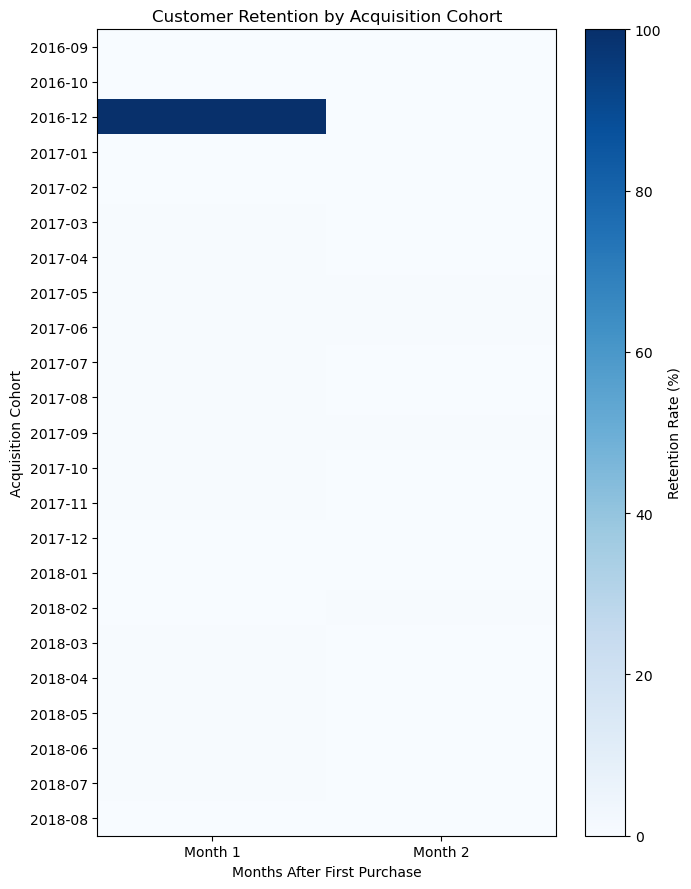

In [13]:

# Create a basic cohort retention heatmap

import matplotlib.pyplot as plt
import numpy as np

# Set cohort month as the row index
heatmap_data = retention_data.set_index("Cohort Month")

# Create the heatmap
plt.figure(figsize=(7, 9))
plt.imshow(heatmap_data, cmap="Blues", aspect="auto")

# Add labels
plt.colorbar(label="Retention Rate (%)")
plt.xticks(
    range(len(heatmap_data.columns)),
    heatmap_data.columns
)
plt.yticks(
    range(len(heatmap_data.index)),
    heatmap_data.index
)

plt.title("Customer Retention by Acquisition Cohort")
plt.xlabel("Months After First Purchase")
plt.ylabel("Acquisition Cohort")

plt.tight_layout()
plt.show()


In [15]:
    
# Load full monthly cohort retention data

import pandas as pd

# Read the full retention CSV exported from SQL Server
full_df = pd.read_csv(
    "../reports/05_Customer_Retention/cohort_retention_full.csv"
)

# Display the dataset size
print("Rows and Columns:", full_df.shape)

# Display the first 5 rows
full_df.head()


Rows and Columns: (219, 5)


,cohort_month,month_number,cohort_size,active_customers,retention_pct
0,2016-09,0,1,1,100.00
1,2016-10,0,262,262,100.00
2,2016-10,6,262,1,0.38
3,2016-10,9,262,1,0.38
4,2016-10,11,262,1,0.38


In [17]:

# Create the cohort retention matrix

# Convert cohort month into a datetime format
full_df["cohort_month"] = pd.to_datetime(
    full_df["cohort_month"]
)

# Arrange retention percentages by cohort and month number
retention_matrix = full_df.pivot(
    index="cohort_month",
    columns="month_number",
    values="retention_pct"
)

# Display the first 5 cohorts
retention_matrix.head()


month_number,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,19,20
cohort_month,,,,,,,,,,,,,,,,,,,,
2016-09-01,100.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2016-10-01,100.0,NaN,NaN,NaN,NaN,NaN,0.38,NaN,NaN,0.38,NaN,0.38,NaN,0.38,NaN,0.38,NaN,0.38,0.76,0.76
2016-12-01,100.0,100.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-01-01,100.0,0.28,0.28,0.14,0.42,0.14,0.42,0.14,0.14,NaN,0.42,0.14,0.70,0.42,0.14,0.14,0.28,0.42,0.14,NaN
2017-02-01,100.0,0.18,0.31,0.12,0.43,0.12,0.25,0.18,0.12,0.18,0.12,0.31,0.12,0.18,0.12,0.06,0.06,0.18,NaN,NaN


In [19]:

# Handle missing retention values correctly

# Find the latest month available in the exported data
last_month = (
    full_df["cohort_month"]
    + full_df["month_number"].apply(
        lambda x: pd.DateOffset(months=int(x))
    )
).max()

# Create a copy of the retention matrix
retention_matrix_clean = retention_matrix.copy()

# Fill missing observed months with 0%
# Keep future months as NaN
for cohort in retention_matrix_clean.index:
    for month in retention_matrix_clean.columns:

        activity_month = cohort + pd.DateOffset(months=int(month))

        if activity_month <= last_month:
            if pd.isna(retention_matrix_clean.loc[cohort, month]):
                retention_matrix_clean.loc[cohort, month] = 0

# Display the cleaned matrix
retention_matrix_clean.head()


C:\Users\gadeb\AppData\Local\Temp\ipykernel_508\1688619477.py:5: PerformanceWarning: Adding/subtracting object-dtype array to DatetimeArray not vectorized.
  full_df["cohort_month"]


month_number,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,19,20
cohort_month,,,,,,,,,,,,,,,,,,,,
2016-09-01,100.0,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
2016-10-01,100.0,0.00,0.00,0.00,0.00,0.00,0.38,0.00,0.00,0.38,0.00,0.38,0.00,0.38,0.00,0.38,0.00,0.38,0.76,0.76
2016-12-01,100.0,100.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
2017-01-01,100.0,0.28,0.28,0.14,0.42,0.14,0.42,0.14,0.14,0.00,0.42,0.14,0.70,0.42,0.14,0.14,0.28,0.42,0.14,NaN
2017-02-01,100.0,0.18,0.31,0.12,0.43,0.12,0.25,0.18,0.12,0.18,0.12,0.31,0.12,0.18,0.12,0.06,0.06,0.18,NaN,NaN


In [21]:

# Calculate the observation cutoff efficiently

# Convert cohort months into month numbers
cohort_numbers = (
    full_df["cohort_month"].dt.year * 12
    + full_df["cohort_month"].dt.month
)

# Find the latest observed activity month
last_month_number = (
    cohort_numbers + full_df["month_number"]
).max()

# Create a copy of the retention matrix
retention_matrix_clean = retention_matrix.copy()

# Fill missing observed months with 0%
# Keep future months as NaN
for cohort in retention_matrix_clean.index:
    for month in retention_matrix_clean.columns:

        activity_month_number = (
            cohort.year * 12 + cohort.month + int(month)
        )

        if activity_month_number <= last_month_number:
            if pd.isna(retention_matrix_clean.loc[cohort, month]):
                retention_matrix_clean.loc[cohort, month] = 0

# Display the corrected matrix
retention_matrix_clean.head()


month_number,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,19,20
cohort_month,,,,,,,,,,,,,,,,,,,,
2016-09-01,100.0,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
2016-10-01,100.0,0.00,0.00,0.00,0.00,0.00,0.38,0.00,0.00,0.38,0.00,0.38,0.00,0.38,0.00,0.38,0.00,0.38,0.76,0.76
2016-12-01,100.0,100.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
2017-01-01,100.0,0.28,0.28,0.14,0.42,0.14,0.42,0.14,0.14,0.00,0.42,0.14,0.70,0.42,0.14,0.14,0.28,0.42,0.14,NaN
2017-02-01,100.0,0.18,0.31,0.12,0.43,0.12,0.25,0.18,0.12,0.18,0.12,0.31,0.12,0.18,0.12,0.06,0.06,0.18,NaN,NaN


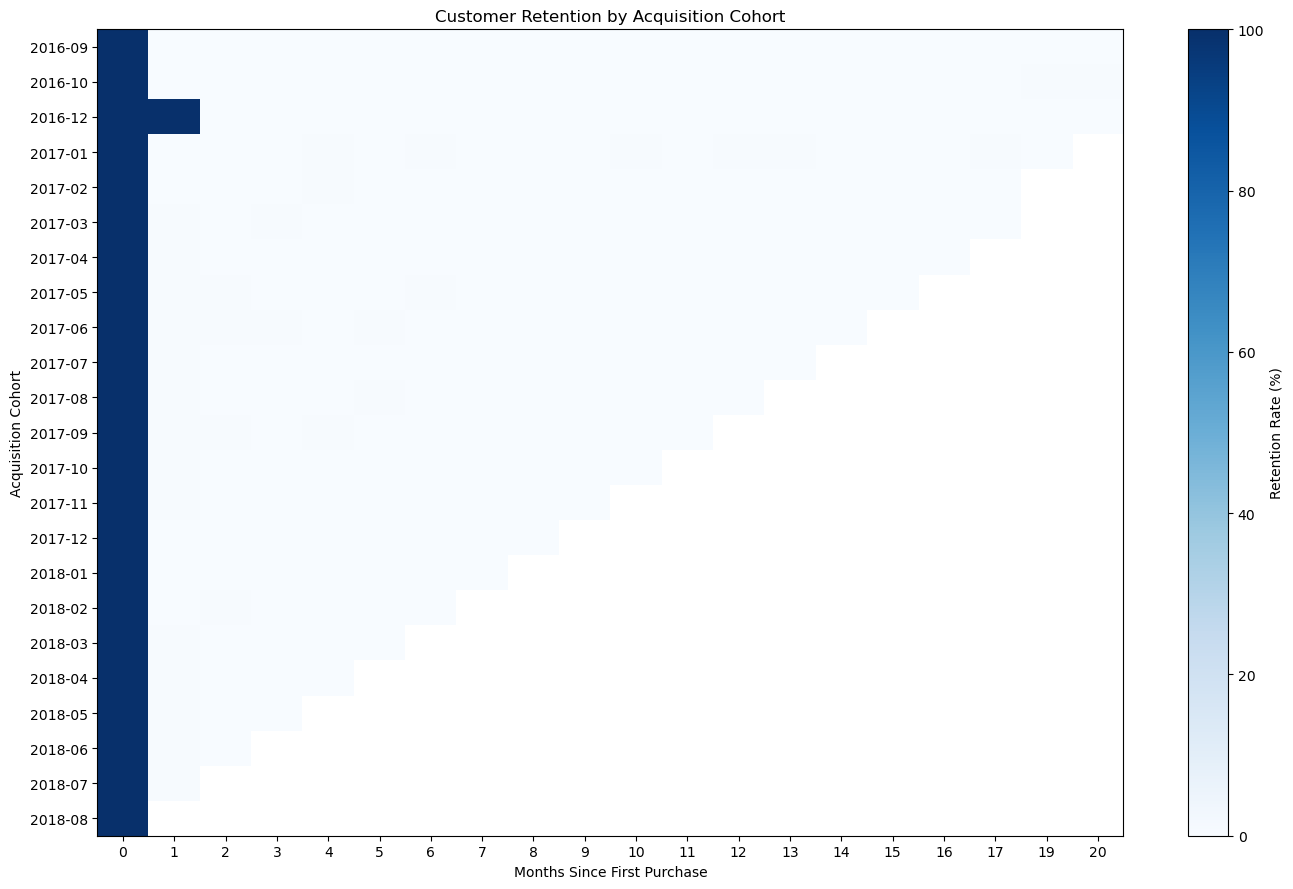

In [23]:

# Create the final cohort retention heatmap

import matplotlib.pyplot as plt
import numpy as np

# Convert retention percentages into a NumPy array
heatmap_values = retention_matrix_clean.to_numpy(dtype=float)

# Hide future months with missing values
masked_values = np.ma.masked_invalid(heatmap_values)

# Create the heatmap
fig, ax = plt.subplots(figsize=(14, 9))

img = ax.imshow(
    masked_values,
    cmap="Blues",
    aspect="auto",
    vmin=0,
    vmax=100
)

# Add labels
ax.set_xticks(range(len(retention_matrix_clean.columns)))
ax.set_xticklabels(retention_matrix_clean.columns)

ax.set_yticks(range(len(retention_matrix_clean.index)))
ax.set_yticklabels(
    retention_matrix_clean.index.strftime("%Y-%m")
)

ax.set_title("Customer Retention by Acquisition Cohort")
ax.set_xlabel("Months Since First Purchase")
ax.set_ylabel("Acquisition Cohort")

# Add the retention percentage color bar
fig.colorbar(img, ax=ax, label="Retention Rate (%)")

# Adjust layout
plt.tight_layout()

# Save the heatmap in the reports folder
plt.savefig(
    "../reports/05_Customer_Retention/cohort_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

# Display the heatmap
plt.show()
